### 1. Imports và configuration

In [1]:
# ============================================================
# Imports and project paths
# ============================================================
import sys
import time
import hashlib
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torchtuples as tt
import matplotlib.pyplot as plt
import seaborn as sns
from lifelines import KaplanMeierFitter
from pycox.models import LogisticHazard

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "examples").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "examples").is_dir():
    raise FileNotFoundError("Run from the project root or a direct subdirectory")
RESULT_DIR = PROJECT_ROOT / "results"
FIGURE_DIR = PROJECT_ROOT / "figures"
RESULT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(PROJECT_ROOT))
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from examples.data.PBC import load_PBC_Seq
from examples.learner.coxsig import CoxSignature
from examples.learner.dynamic_deephit_ext import construct_df, Dynamic_DeepHit_ext
from examples.learner.DySurv.model_utils import DySurv, Loss
from examples.learner.dysurv_ext import DySurvWrapper, make_dysurv_input, add_duration_channel
from examples.learner.utils import score
from explanation_plot_utils import (
    DEFAULT_COLORS, load_explanations, importance_summary, explanation_array,
    plot_global, plot_temporal, style_axis,
)

warnings.filterwarnings("ignore")
sns.set(style="whitegrid", font="STIXGeneral", context="talk", palette="colorblind")

seed = 0
SEED = seed
np.random.seed(SEED)
torch.manual_seed(SEED)

train_test_share = 0.8
train_ratio = train_test_share
val_ratio = 0.1
sig_order, coxsig_alpha, coxsig_max_iter = 2, 5e-2, 100
num_durations, latent_dim = 10, 20
batch_size, epochs, learning_rate, patience = 32, 200, 1e-3, 20
quantile_pred_times = np.array([0.25, 0.50])
n_eval_times, eval_quantile_step = 3, 0.15
FORCE_RETRAIN_DYSURV = False
FORCE_RETRAIN_DDH = False

MODEL_LABELS = {"CoxSig": "CoxSig explanation", "DDH": "DDH explanation", "DySurv": "DySurv explanation"}
COLORS = DEFAULT_COLORS

/Users/vantnguy/Working/survinsights/.venv_survinsights_longi/lib/python3.12/site-packages/rpy2/rinterface/__init__.py:1211: UserWarning: Environment variable "PWD" redefined by R and overriding existing variable. Current: "/", R: "/Users/vantnguy/Working/survinsights/notebooks"
  warnings.warn(
/Users/vantnguy/Working/survinsights/.venv_survinsights_longi/lib/python3.12/site-packages/rpy2/rinterface/__init__.py:1211: UserWarning: Environment variable "R_SESSION_TMPDIR" redefined by R and overriding existing variable. Current: "/var/folders/6h/mbpmjgv92rd7jy5b7j17vhzrt2jftk/T//Rtmpiltpg7", R: "/var/folders/6h/mbpmjgv92rd7jy5b7j17vhzrt2jftk/T//Rtmpf49WBV"
  warnings.warn(
/Users/vantnguy/Working/survinsights/.venv_survinsights_longi/lib/python3.12/site-packages/keras/src/export/tf2onnx_lib.py:8: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, "object"):


### 2. PBC-Seq dataset và train/test split

In [2]:
# ============================================================
# Load PBC-Seq dataset
# ============================================================

paths, surv_labels, longi_feat_list, static_feature, \
    static_feature_list, ddh_info_sup = load_PBC_Seq.load()

longi_feat_list = [
    "serBilir",
    "albumin",
    "alkaline",
    "SGOT",
    "protime",
]

n_samples, n_sampling_times, _ = paths.shape
n_longi_feats = paths.shape[-1] - 1

sampling_times = np.asarray(paths[0, :, 0])
surv_times = np.asarray(surv_labels[:, 0])
surv_inds = np.asarray(surv_labels[:, 1])

dt = float(sampling_times[1] - sampling_times[0])

print(f"Dataset: PBC-Seq")
print(f"Number of samples: {n_samples}")
print(f"Longitudinal features: {n_longi_feats}")
print(f"Static features: {0 if static_feature is None else static_feature.shape[1]}")

# ============================================================
# Train / validation / test split
# ============================================================

n_train = int(train_test_share * n_samples)

indices = np.random.permutation(n_samples)
train_index = indices[:n_train]
test_index = indices[n_train:]

n_fit = int((1 - val_ratio) * len(train_index))
fit_index = train_index[:n_fit]
val_index = train_index[n_fit:]

paths_train = paths[train_index]
paths_test = paths[test_index]

surv_labels_train = surv_labels[train_index]
surv_labels_test = surv_labels[test_index]

static_feature_train = (
    None if static_feature is None
    else static_feature[train_index]
)

static_feature_test = (
    None if static_feature is None
    else static_feature[test_index]
)

print(f"Train: {len(train_index)}")
print(f"  Fit: {len(fit_index)}")
print(f"  Validation: {len(val_index)}")
print(f"Test: {len(test_index)}")


# ============================================================
# Prediction times and evaluation horizons
# ============================================================

tte = np.asarray(surv_labels)
tte = tte[tte[:, 1] == 1, 0]

pred_times = (
    (
        np.quantile(tte, quantile_pred_times) - 2 * dt
    ) // dt
) * dt

eval_times = np.array([
    np.max(
        np.quantile(
            tte,
            np.minimum(
                quantile_pred_times + (k + 1) * eval_quantile_step,
                1.0,
            ),
        ) - pred_times
    )
    for k in range(n_eval_times)
])

print("Prediction times:", pred_times)
print("Evaluation horizons:", eval_times)

R callback write-console: Loading required package: nlme
  
R callback write-console: Loading required package: survival
  
R callback write-console: Loading required package: doParallel
  
R callback write-console: Loading required package: foreach
  
R callback write-console: Loading required package: iterators
  
R callback write-console: Loading required package: parallel
  
R callback write-console: Loading required package: rstan
  
R callback write-console: Loading required package: StanHeaders
  
R callback write-console: 
rstan version 2.32.7 (Stan version 2.32.2)

  
R callback write-console: For execution on a local, multicore CPU with excess RAM we recommend calling
options(mc.cores = parallel::detectCores()).
To avoid recompilation of unchanged Stan programs, we recommend calling
rstan_options(auto_write = TRUE)
For within-chain threading using `reduce_sum()` or `map_rect()` Stan functions,
change `threads_per_chain` option:
rstan_options(threads_per_chain = 1)

  


Index(['id', 'years', 'status', 'drug', 'age', 'sex', 'year', 'ascites',
       'hepatomegaly', 'spiders', 'edema', 'serBilir', 'serChol', 'albumin',
       'alkaline', 'SGOT', 'platelets', 'prothrombin', 'histologic', 'status2',
       'times', 'tte', 'label'],
      dtype='object')
Dataset: PBC-Seq
Number of samples: 285
Longitudinal features: 5
Static features: 2
Train: 228
  Fit: 205
  Validation: 23
Test: 57
Prediction times: [2.35000004 3.95000006]
Evaluation horizons: [1.76299974 3.81399988 6.12649988]


### 3. Train and evaluate CoxSig

In [3]:
# ============================================================
# CoxSig training
# ============================================================

print("\n========== CoxSig ==========")

coxsig = CoxSignature(
    sig_level=sig_order,
    alphas=coxsig_alpha,
    max_iter=coxsig_max_iter,
)

start = time.time()

coxsig.train(
    paths_train,
    surv_labels_train,
    static_feature_train,
    plot_loss=False,
)

print(f"CoxSig training time: {time.time() - start:.2f}s")


# ============================================================
# CoxSig evaluation
# ============================================================

coxsig_cindex = coxsig.score(
    paths_test,
    surv_labels_test,
    pred_times,
    eval_times,
    "c_index",
    static_feat=static_feature_test,
)

coxsig_bs = coxsig.score(
    paths_test,
    surv_labels_test,
    pred_times,
    eval_times,
    "bs",
    static_feat=static_feature_test,
)

print("C-index:\n", coxsig_cindex)
print("Brier score:\n", coxsig_bs)


========== CoxSig ==========
CoxSig training time: 2.01s
C-index:
 [[0.52631579 0.50619835 0.4637931 ]
 [0.5472973  0.5078125  0.51132686]]
Brier score:
 [[0.12689072 0.20623767 0.28620143]
 [0.0965754  0.2128489  0.36975348]]


### 4. Train and evaluate Dynamic DeepHit

In [4]:
# ============================================================
# Dynamic DeepHit preprocessing
# ============================================================

print("\n========== Dynamic DeepHit ==========")

cont_feat, bin_feat, time_scale, bin_df = ddh_info_sup

paths_torch = (
    paths.clone()
    if isinstance(paths, torch.Tensor)
    else torch.as_tensor(paths).clone()
)

df = construct_df(
    paths_torch,
    surv_labels,
    cont_feat,
    bin_feat,
    time_scale,
    bin_df,
)

dynamic_deephit = Dynamic_DeepHit_ext()

(data, time_, label), (mask1, mask2, mask3), data_mi = (
    dynamic_deephit.preprocess(df, cont_feat, bin_feat)
)

dynamic_deephit.sampling_times = sampling_times
dynamic_deephit.ddh_info_sup = ddh_info_sup

# ---------- Split preprocessed data ----------
tr_data = data[train_index]
te_data = data[test_index]

tr_data_mi = data_mi[train_index]
te_data_mi = data_mi[test_index]

tr_time = time_[train_index]
tr_label = label[train_index]

tr_mask1 = mask1[train_index]
tr_mask2 = mask2[train_index]
tr_mask3 = mask3[train_index]

tr_data_full = (
    tr_data,
    tr_data_mi,
    tr_label,
    tr_time,
    tr_mask1,
    tr_mask2,
    tr_mask3,
)


# ============================================================
# Dynamic DeepHit training
# ============================================================

ckpt_dir = RESULT_DIR / "dynamic_deephit_ckpt" / "PBC"
ckpt_dir.mkdir(parents=True, exist_ok=True)
checkpoint_path = ckpt_dir / "model.weights.h5"
DDH_IS_TRAINED = checkpoint_path.is_file() and not FORCE_RETRAIN_DDH

start = time.time()
dynamic_deephit.train(
    tr_data_full,
    is_trained=DDH_IS_TRAINED,
    ckpt_dir=str(ckpt_dir),
    plot_loss=False,
)

print(f"DDH training/loading time: {time.time() - start:.2f}s")


# ============================================================
# Dynamic DeepHit evaluation
# ============================================================

pred_time_scale = (pred_times * time_scale).astype(int)
eval_time_scale = (eval_times * time_scale).astype(int)

ddh_surv_preds = dynamic_deephit.predict(
    te_data,
    te_data_mi,
    pred_time_scale,
    eval_time_scale,
)

shape = (len(pred_times), len(eval_times))

ddh_cindex = np.full(shape, np.nan)
ddh_bs = np.full(shape, np.nan)

for j, pred_time in enumerate(pred_times):
    # ---------- Select at-risk test individuals ----------
    idx_sel = surv_labels_test[:, 0] >= pred_time

    surv_times_ = (
        np.asarray(surv_labels_test[idx_sel, 0]) - pred_time
    )

    surv_inds_ = np.asarray(
        surv_labels_test[idx_sel, 1]
    )

    surv_labels_ = np.column_stack([
        surv_times_,
        surv_inds_,
    ])

    surv_preds_ = ddh_surv_preds[:, j][idx_sel]

    ddh_cindex[j] = score(
        "c_index",
        surv_labels_,
        surv_labels_,
        surv_preds_,
        eval_times,
    )

    ddh_bs[j] = score(
        "bs",
        surv_labels_,
        surv_labels_,
        surv_preds_,
        eval_times,
    )

print("C-index:\n", ddh_cindex)
print("Brier score:\n", ddh_bs)


========== Dynamic DeepHit ==========
DDH training/loading time: 0.75s
C-index:
 [[0.95065789 0.86363636 0.82758621]
 [0.81756757 0.66015625 0.69579288]]
Brier score:
 [[0.11611614 0.18878867 0.23863825]
 [0.09462987 0.1921937  0.26304258]]


### 5. Train and evaluate DySurv

In [5]:
# ============================================================
# DySurv preprocessing
# ============================================================

print("\n========== DySurv ==========")

paths_np = np.asarray(paths, dtype=np.float32)
surv_labels_np = np.asarray(surv_labels, dtype=np.float32)

static_feature_np = (
    None if static_feature is None
    else np.asarray(static_feature, dtype=np.float32)
)

# ---------- Prepare training and validation data ----------
x_fit = make_dysurv_input(
    paths_np[fit_index],
    None if static_feature_np is None
    else static_feature_np[fit_index],
)

x_val = make_dysurv_input(
    paths_np[val_index],
    None if static_feature_np is None
    else static_feature_np[val_index],
)

# ---------- Duration discretization ----------
labtrans = LogisticHazard.label_transform(num_durations)

y_fit = labtrans.fit_transform(
    surv_labels_np[fit_index, 0],
    surv_labels_np[fit_index, 1].astype(int),
)

y_val = labtrans.transform(
    surv_labels_np[val_index, 0],
    surv_labels_np[val_index, 1].astype(int),
)

# ---------- Add duration-index channel ----------
train_input = add_duration_channel(x_fit, y_fit)
val_input = add_duration_channel(x_val, y_val)

train = tt.tuplefy(
    train_input,
    (y_fit, train_input),
)

val = tt.tuplefy(
    val_input,
    (y_val, val_input),
)


# ============================================================
# DySurv training
# ============================================================

net = DySurv(
    in_features=x_fit.shape[2],
    encoded_features=latent_dim,
    out_features=labtrans.out_features,
    seq_len=x_fit.shape[1],
)

dysurv_model = LogisticHazard(
    net,
    tt.optim.Adam(learning_rate),
    duration_index=labtrans.cuts,
    loss=Loss([1.0, 0.1, 0.01]),
)


# ---------- Dataset-aware checkpoint ----------
def array_digest(*arrays):
    digest = hashlib.sha256()
    for array in arrays:
        if array is None:
            digest.update(b"none")
            continue
        array = np.ascontiguousarray(np.asarray(array))
        digest.update(str((array.shape, array.dtype)).encode())
        digest.update(array.tobytes())
    return digest.hexdigest()

checkpoint_path = RESULT_DIR / "dysurv_ckpt" / "PBC" / "model.pt"
checkpoint_path.parent.mkdir(parents=True, exist_ok=True)
checkpoint_config = {
    "num_durations": num_durations,
    "latent_dim": latent_dim,
    "input_shape": tuple(x_fit.shape[1:]),
    "data_digest": array_digest(paths_np, surv_labels_np, static_feature_np,
                                train_index, test_index, fit_index, val_index),
}

start = time.time()
if checkpoint_path.is_file() and not FORCE_RETRAIN_DYSURV:
    checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=False)
    if checkpoint.get("config") != checkpoint_config:
        raise ValueError("DySurv checkpoint/data mismatch; set FORCE_RETRAIN_DYSURV=True")
    if not np.allclose(checkpoint["duration_index"], labtrans.cuts):
        raise ValueError("DySurv duration cuts mismatch; set FORCE_RETRAIN_DYSURV=True")
    dysurv_model.net.load_state_dict(checkpoint["model_state_dict"])
    print(f"Loaded DySurv checkpoint: {checkpoint_path}")
else:
    dysurv_log = dysurv_model.fit(
        *train, batch_size=batch_size, epochs=epochs, val_data=val,
        callbacks=[tt.cb.EarlyStopping(patience=patience)], verbose=False,
    )
    torch.save({"model_state_dict": dysurv_model.net.state_dict(),
                "duration_index": np.asarray(labtrans.cuts),
                "config": checkpoint_config}, checkpoint_path)
    print(f"Saved DySurv checkpoint: {checkpoint_path}")

dysurv_model.net.eval()
print(f"DySurv training/loading time: {time.time() - start:.2f}s")

dysurv = DySurvWrapper(dysurv_model)


# ============================================================
# DySurv evaluation
# ============================================================

# ---------- Censoring distribution from training set ----------
censor_km = KaplanMeierFitter()

censor_km.fit(
    durations=surv_labels_train[:, 0],
    event_observed=1 - np.asarray(
        surv_labels_train[:, 1]
    ).astype(int),
)

dysurv_cindex = np.full(shape, np.nan)
dysurv_bs = np.full(shape, np.nan)

for j, pred_time in enumerate(pred_times):
    dysurv_cindex[j] = dysurv.score(
        paths_np[test_index],
        surv_labels_np[test_index],
        pred_time,
        eval_times,
        metric="c_index",
        static_feat=(
            None if static_feature_np is None
            else static_feature_np[test_index]
        ),
    )

    dysurv_bs[j] = dysurv.score(
        paths_np[test_index],
        surv_labels_np[test_index],
        pred_time,
        eval_times,
        metric="bs",
        static_feat=(
            None if static_feature_np is None
            else static_feature_np[test_index]
        ),
        censor_km=censor_km,
    )

print("C-index:\n", dysurv_cindex)
print("Brier score:\n", dysurv_bs)


========== DySurv ==========
Loaded DySurv checkpoint: /Users/vantnguy/Working/survinsights/results/dysurv_ckpt/PBC/model.pt
DySurv training/loading time: 0.00s
C-index:
 [[0.94407895 0.86157025 0.82068966]
 [0.84459459 0.69921875 0.72168285]]
Brier score:
 [[0.0853658  0.16448403 0.28974445]
 [0.09314806 0.2369872  0.27238282]]


### 6. Comparison và visualization

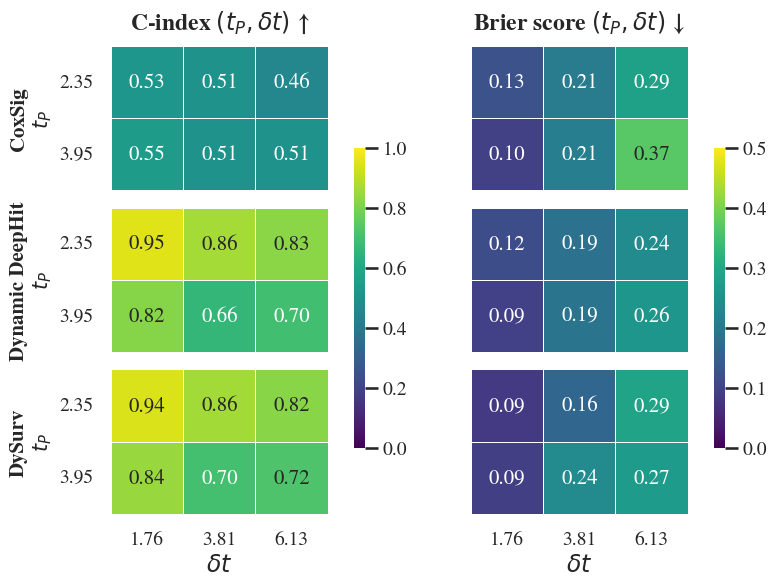


========== Model comparison ==========
          Model  Mean C-index  Mean Brier score
         CoxSig        0.5105            0.2164
Dynamic DeepHit        0.8026            0.1822
         DySurv        0.8153            0.1904

Saved PBC-Seq evaluation results.


In [6]:
# ============================================================
# Compact performance heatmaps
# ============================================================

models = ["CoxSig", "Dynamic DeepHit", "DySurv"]
cindex_results = [coxsig_cindex, ddh_cindex, dysurv_cindex]
bs_results = [coxsig_bs, ddh_bs, dysurv_bs]

fig, axs = plt.subplots(3, 2, figsize=(9, 6))
plt.subplots_adjust(
    left=0.16, right=0.88, bottom=0.12, top=0.90,
    hspace=0.12, wspace=0.25,
)

# ---------- Shared colorbars ----------
cbar_ax_1 = fig.add_axes([0.47, 0.23, 0.012, 0.50])
cbar_ax_2 = fig.add_axes([0.87, 0.23, 0.012, 0.50])

# ---------- Heatmaps ----------
for i, model in enumerate(models):
    for j, (values, vmin, vmax, cbar_ax) in enumerate([
        (cindex_results[i], 0, 1, cbar_ax_1),
        (bs_results[i], 0, 0.5, cbar_ax_2),
    ]):
        ax = axs[i, j]

        sns.heatmap(
            values,
            annot=True,
            fmt=".2f",
            annot_kws={"size": 15},
            cmap="viridis",
            vmin=vmin,
            vmax=vmax,
            square=True,
            linewidths=0.5,
            linecolor="white",
            ax=ax,
            cbar=(i == 2),
            cbar_ax=cbar_ax if i == 2 else None,
        )

        # ---------- Shared x-axis labels ----------
        if i == 2:
            ax.set_xticklabels(
                [f"{x:.2f}" for x in eval_times],
                rotation=0,
                fontsize=14,
            )
            ax.set_xlabel(
                r"$\delta t$",
                fontsize=17,
                fontweight="semibold",
            )
        else:
            ax.set_xticks([])

        # ---------- Shared y-axis labels ----------
        if j == 0:
            ax.set_yticklabels(
                [f"{x:.2f}" for x in pred_times],
                rotation=0,
                fontsize=14,
            )
            ax.set_ylabel(
                f"{model}\n$t_P$",
                fontsize=15,
                fontweight="semibold",
            )
        else:
            ax.set_yticks([])
            ax.set_ylabel("")

        if i == 0:
            ax.set_title(
                r"C-index $(t_P,\delta t)$ ↑" if j == 0
                else r"Brier score $(t_P,\delta t)$ ↓",
                fontsize=17,
                fontweight="semibold",
                pad=12,
            )

# ---------- Colorbar formatting ----------
for cbar_ax in [cbar_ax_1, cbar_ax_2]:
    cbar_ax.tick_params(labelsize=14)

# ---------- Save figure ----------
fig.savefig(
    FIGURE_DIR / "PBC_perf_comparison.pdf",
    bbox_inches="tight",
    dpi=300,
)

plt.show()


# ============================================================
# Save evaluation results
# ============================================================

results = {
    model: (cindex, bs)
    for model, cindex, bs in zip(models, cindex_results, bs_results)
}

for model_name, (cindex, bs) in results.items():
    name = model_name.replace(" ", "_")

    np.save(RESULT_DIR / f"PBC_{name}_cindex.npy", cindex)
    np.save(RESULT_DIR / f"PBC_{name}_bs.npy", bs)

np.savez(
    RESULT_DIR / "PBC_experiment_config.npz",
    train_index=train_index,
    test_index=test_index,
    fit_index=fit_index,
    val_index=val_index,
    pred_times=pred_times,
    eval_times=eval_times,
    seed=seed,
)

# ---------- Summary table ----------
summary = pd.DataFrame([
    {
        "Model": model,
        "Mean C-index": np.nanmean(cindex),
        "Mean Brier score": np.nanmean(bs),
    }
    for model, (cindex, bs) in results.items()
])

summary.to_csv(
    RESULT_DIR / "PBC_model_comparison.csv",
    index=False,
)

print("\n========== Model comparison ==========")
print(summary.round(4).to_string(index=False))
print("\nSaved PBC-Seq evaluation results.")

### 7. Explanation utilities

In [7]:
FEATURE_LABELS = list(longi_feat_list) + list(static_feature_list)
N_STATIC = len(FEATURE_LABELS) - n_longi_feats

def get_summaries(kind="mean", temporal_ci_mode="legacy"):
    results = load_explanations(RESULT_DIR, "PBC", kind, MODEL_LABELS)
    return {
        model: [importance_summary(result, idx, temporal_ci_mode)
                for idx in range(len(result))]
        for model, result in results.items()
    }

def explanation_end_time(summary):
    # Preserve the original PBC convention for the plotted endpoint.
    last_idx = np.sum(~np.isnan(summary.temporal_mean[0])) - 1
    return (last_idx - 1) * dt

def save_figure(fig, filename):
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / filename, bbox_inches="tight", dpi=300)
    plt.show()

### 8. Main model comparisons — global and interval-wise importance

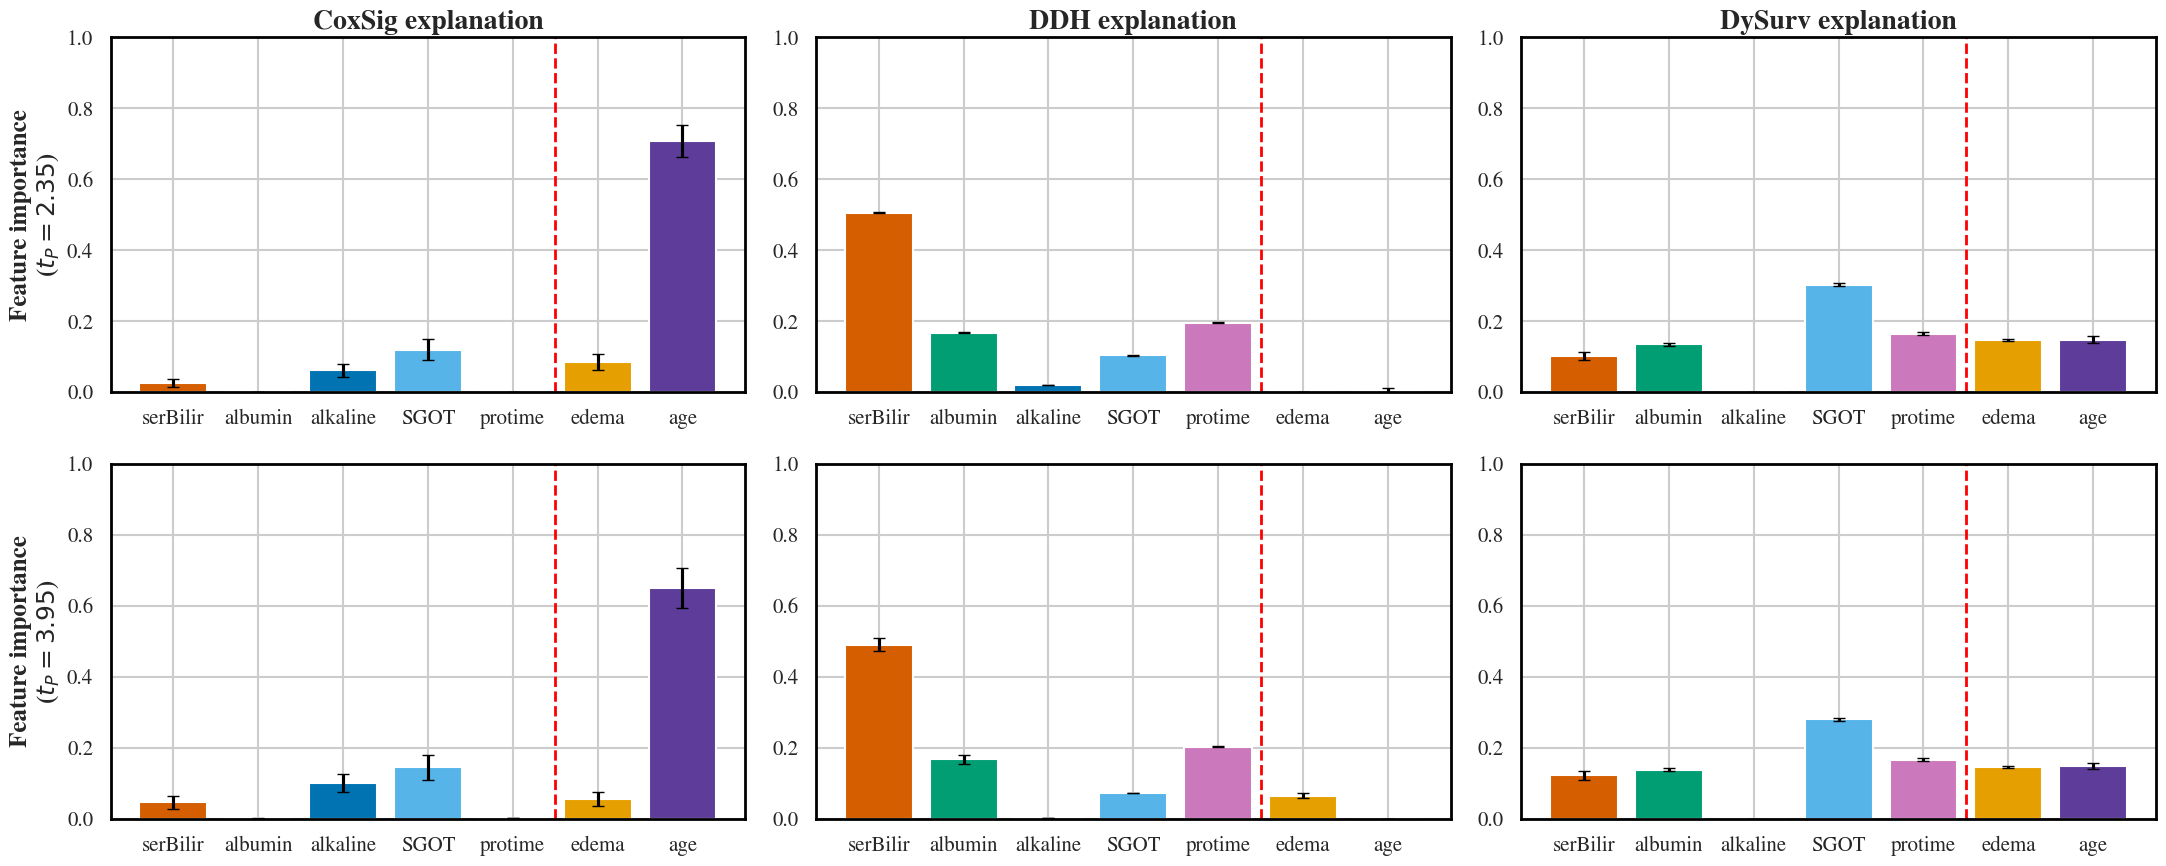

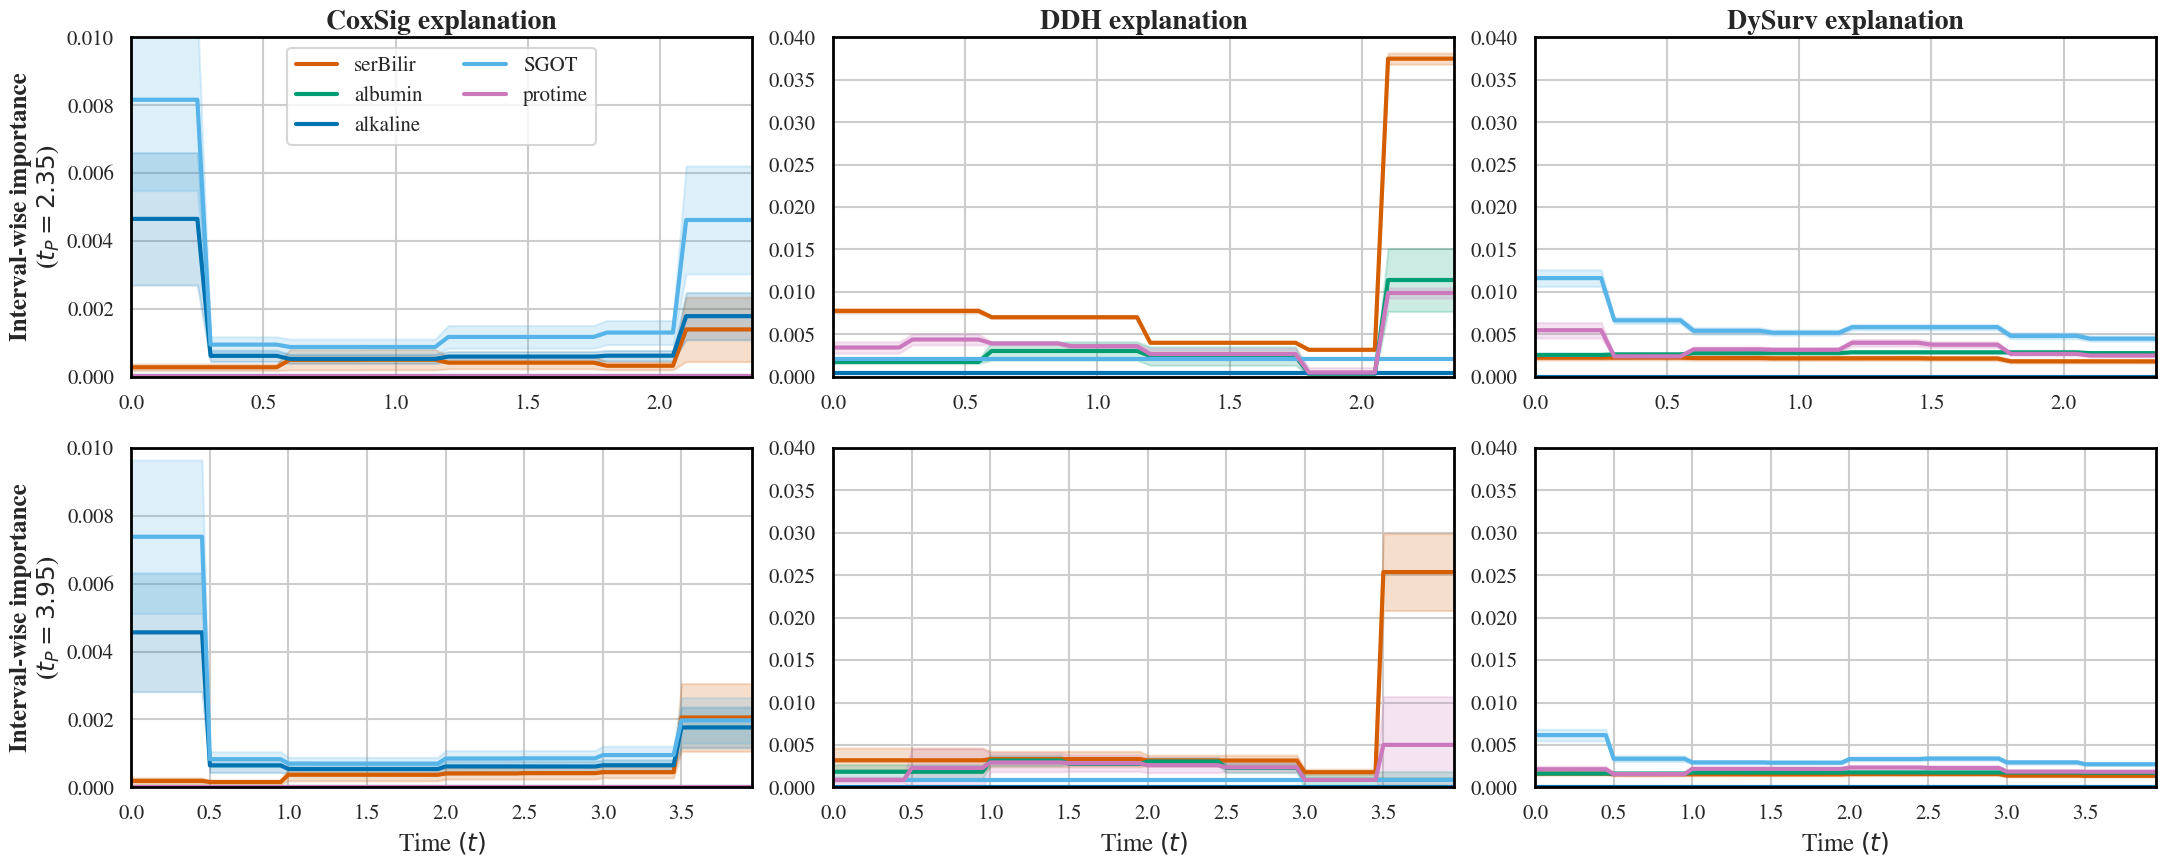

In [8]:
# ============================================================
# Global and temporal importance across prediction times
# ============================================================

def compare_models(explanation_kind="mean", view="global", y_limits=None):
    summaries = get_summaries(explanation_kind)
    fig, axes = plt.subplots(len(pred_times), len(MODEL_LABELS),
                             figsize=(22, 4.5 * len(pred_times)), squeeze=False)

    for prediction_idx in range(len(pred_times)):
        for col, model in enumerate(MODEL_LABELS):
            summary = summaries[model][prediction_idx]
            ax = axes[prediction_idx, col]

            if view == "global":
                plot_global(ax, summary.global_mean, summary.global_ci,
                            labels=FEATURE_LABELS, colors=COLORS,
                            separator=n_longi_feats - 0.5)
            elif view == "temporal":
                plot_temporal(ax, summary.temporal_mean, summary.temporal_ci,
                              sampling_times, n_longi_feats, FEATURE_LABELS, COLORS)
                ax.set_xlim(0, explanation_end_time(summary))
                if prediction_idx == len(pred_times) - 1:
                    ax.set_xlabel(r"Time $(t)$", fontsize=18)
            else:
                raise ValueError("view must be 'global' or 'temporal'")

            limit = None if y_limits is None else (
                y_limits.get(model) if isinstance(y_limits, dict) else y_limits[prediction_idx]
            )
            style_axis(ax, MODEL_LABELS[model] if prediction_idx == 0 else None, limit)

            if col == 0:
                axes[prediction_idx, 0].set_ylabel(
                ("Feature" if view == "global" else "Interval-wise") 
                + f" importance\n($t_P={pred_times[prediction_idx]:.2f}$)", fontweight="semibold")

    if view == "temporal":
        axes[0, 0].legend(ncols=2, fontsize=15, loc="upper center")

    suffix = "feat" if view == "global" else "longi"
    save_figure(fig, f"shap_PBC_{explanation_kind}_score_per_{suffix}.pdf")

compare_models("mean", "global", y_limits=[(0, 1)] * len(pred_times))
compare_models("mean", "temporal", y_limits={
    "CoxSig": (0, 0.01), "DDH": (0, 0.04), "DySurv": (0, 0.04),
})

### 9. Single prediction-time comparison

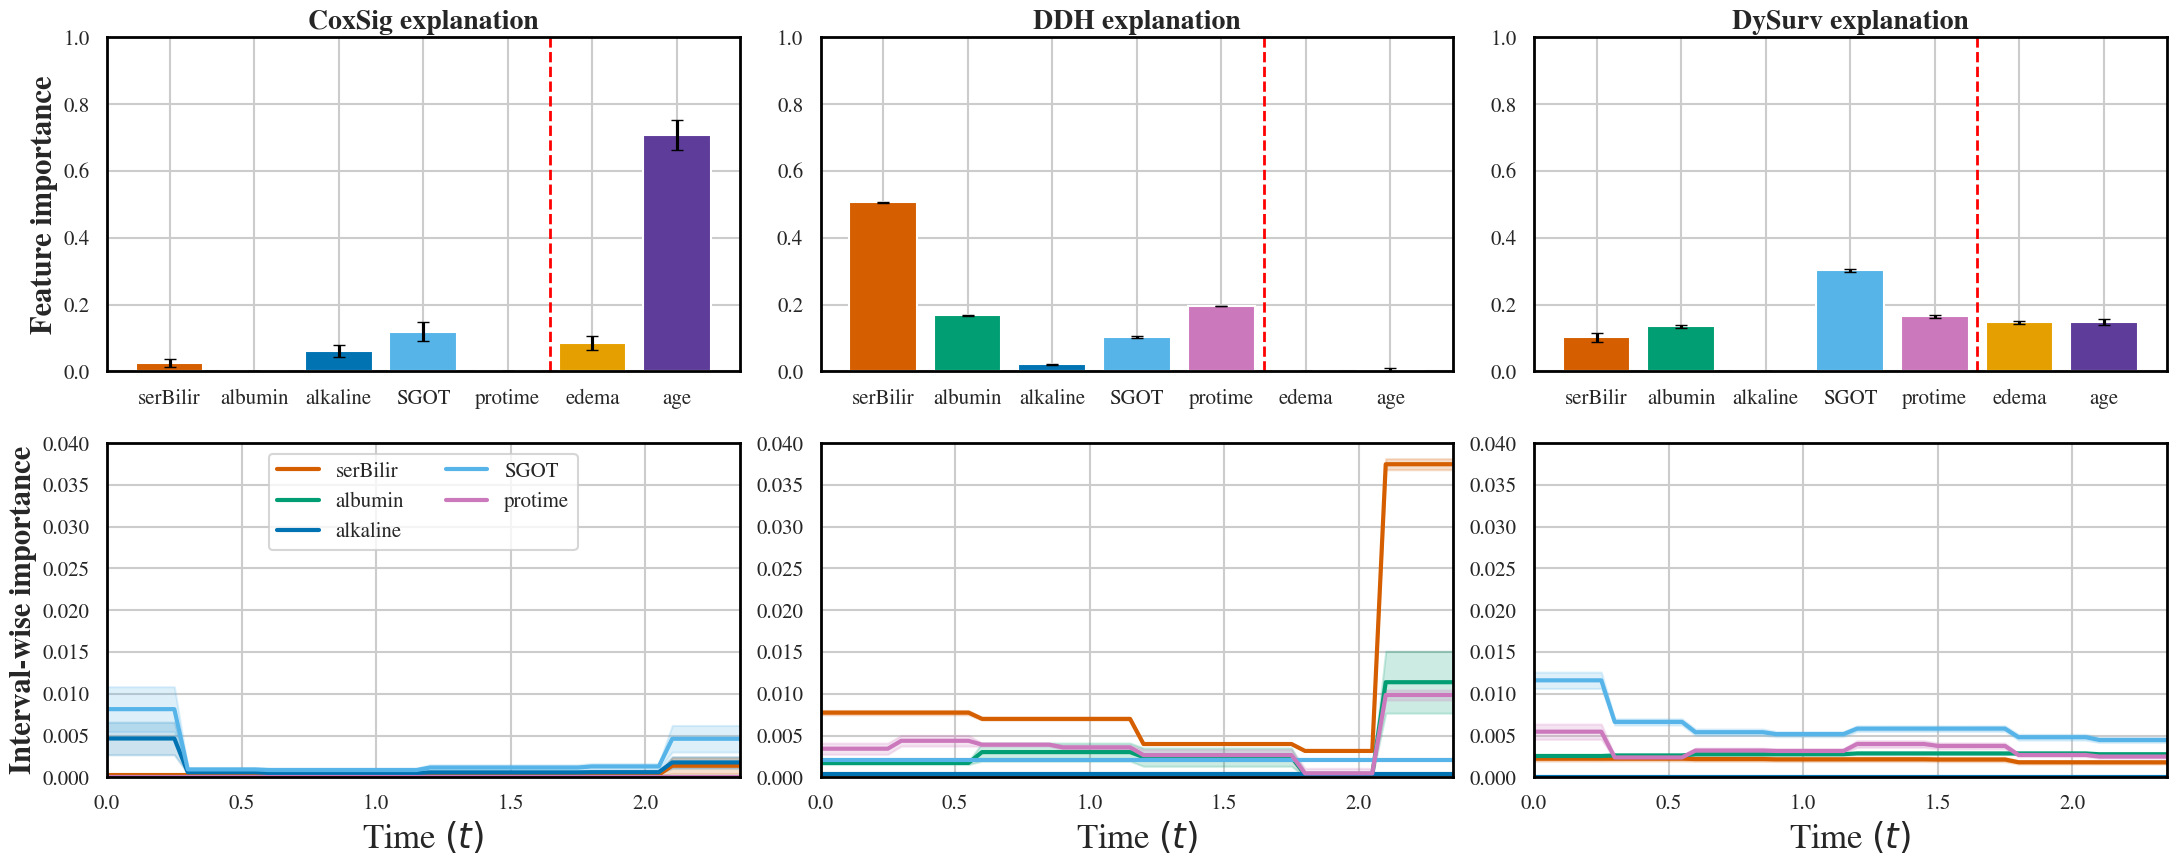

In [9]:
prediction_idx = 0
explanation_kind = "mean"
summaries = get_summaries(explanation_kind)
ylims = [(0, 1), (0, 0.04)]
fig, axes = plt.subplots(2, 3, figsize=(22, 9))

for col, model in enumerate(MODEL_LABELS):
    summary = summaries[model][prediction_idx]
    plot_global(axes[0, col], summary.global_mean, summary.global_ci,
                labels=FEATURE_LABELS, colors=COLORS, separator=n_longi_feats - 0.5, fontsize=25)
    plot_temporal(axes[1, col], summary.temporal_mean, summary.temporal_ci,
                  sampling_times, n_longi_feats, FEATURE_LABELS, COLORS)

    for row in range(2):
        style_axis(axes[row, col], MODEL_LABELS[model] if row == 0 else None, ylims[row])
    axes[1, col].set_xlim(0, explanation_end_time(summary))
    axes[1, col].set_xlabel("Time $(t)$", fontsize=25)

axes[0, 0].set_ylabel("Feature importance", fontsize=22, fontweight="semibold")
axes[1, 0].set_ylabel("Interval-wise importance", fontsize=22, fontweight="semibold")
axes[1, 0].legend(ncols=2, fontsize=15, loc="upper center")
save_figure(fig, f"shap_PBC_{explanation_kind}_score_1pt.pdf")

### 10. Threshold selection ($\delta_1$)

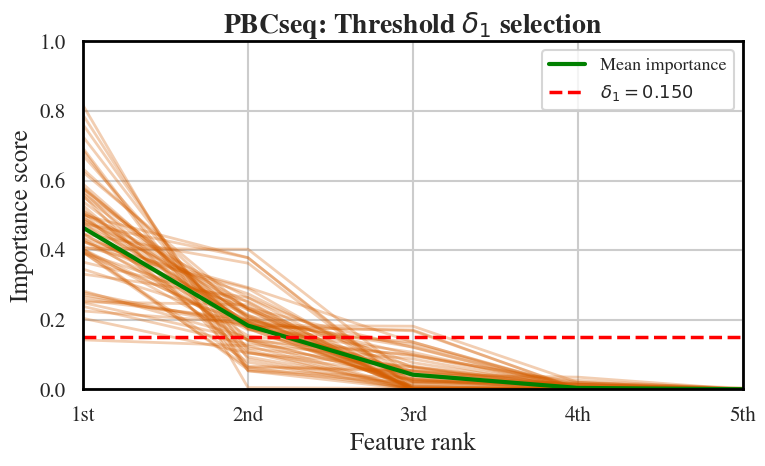

In [10]:
model_name = "CoxSig"
prediction_idx = 1
delta_1 = 0.15
explanation_kind = "mean"
model_results = load_explanations(RESULT_DIR, "PBC", explanation_kind, MODEL_LABELS)
values = explanation_array(model_results[model_name], prediction_idx)
importance = np.nansum(values[:, :n_longi_feats], axis=-1)
importance = importance[np.any(importance != 0, axis=1)]
ranked_importance = np.sort(importance, axis=1)[:, ::-1]
mean_importance = ranked_importance.mean(axis=0)

fig, ax = plt.subplots(figsize=(8, 5))
for values in ranked_importance:
    ax.plot(np.arange(1, n_longi_feats + 1), values, color="r", lw=2, alpha=0.3)
ax.plot(np.arange(1, n_longi_feats + 1), mean_importance, color="green", lw=3, label="Mean importance")
ax.axhline(delta_1, color="red", ls="--", lw=2.5, label=rf"$\delta_1 = {delta_1:.3f}$")
ax.set_xticks(np.arange(1, n_longi_feats + 1), ["1st", "2nd", "3rd", "4th", "5th"][:n_longi_feats])
ax.set_xlim(1, n_longi_feats)
ax.set_ylim(0, 1)
ax.set_xlabel("Feature rank")
ax.set_ylabel("Importance score")
style_axis(ax, rf"PBCseq: Threshold $\delta_1$ selection")
ax.legend(fontsize=13)
save_figure(fig, f"PBC_{model_name}_delta1_selection.pdf")

### 11. Median-target figures

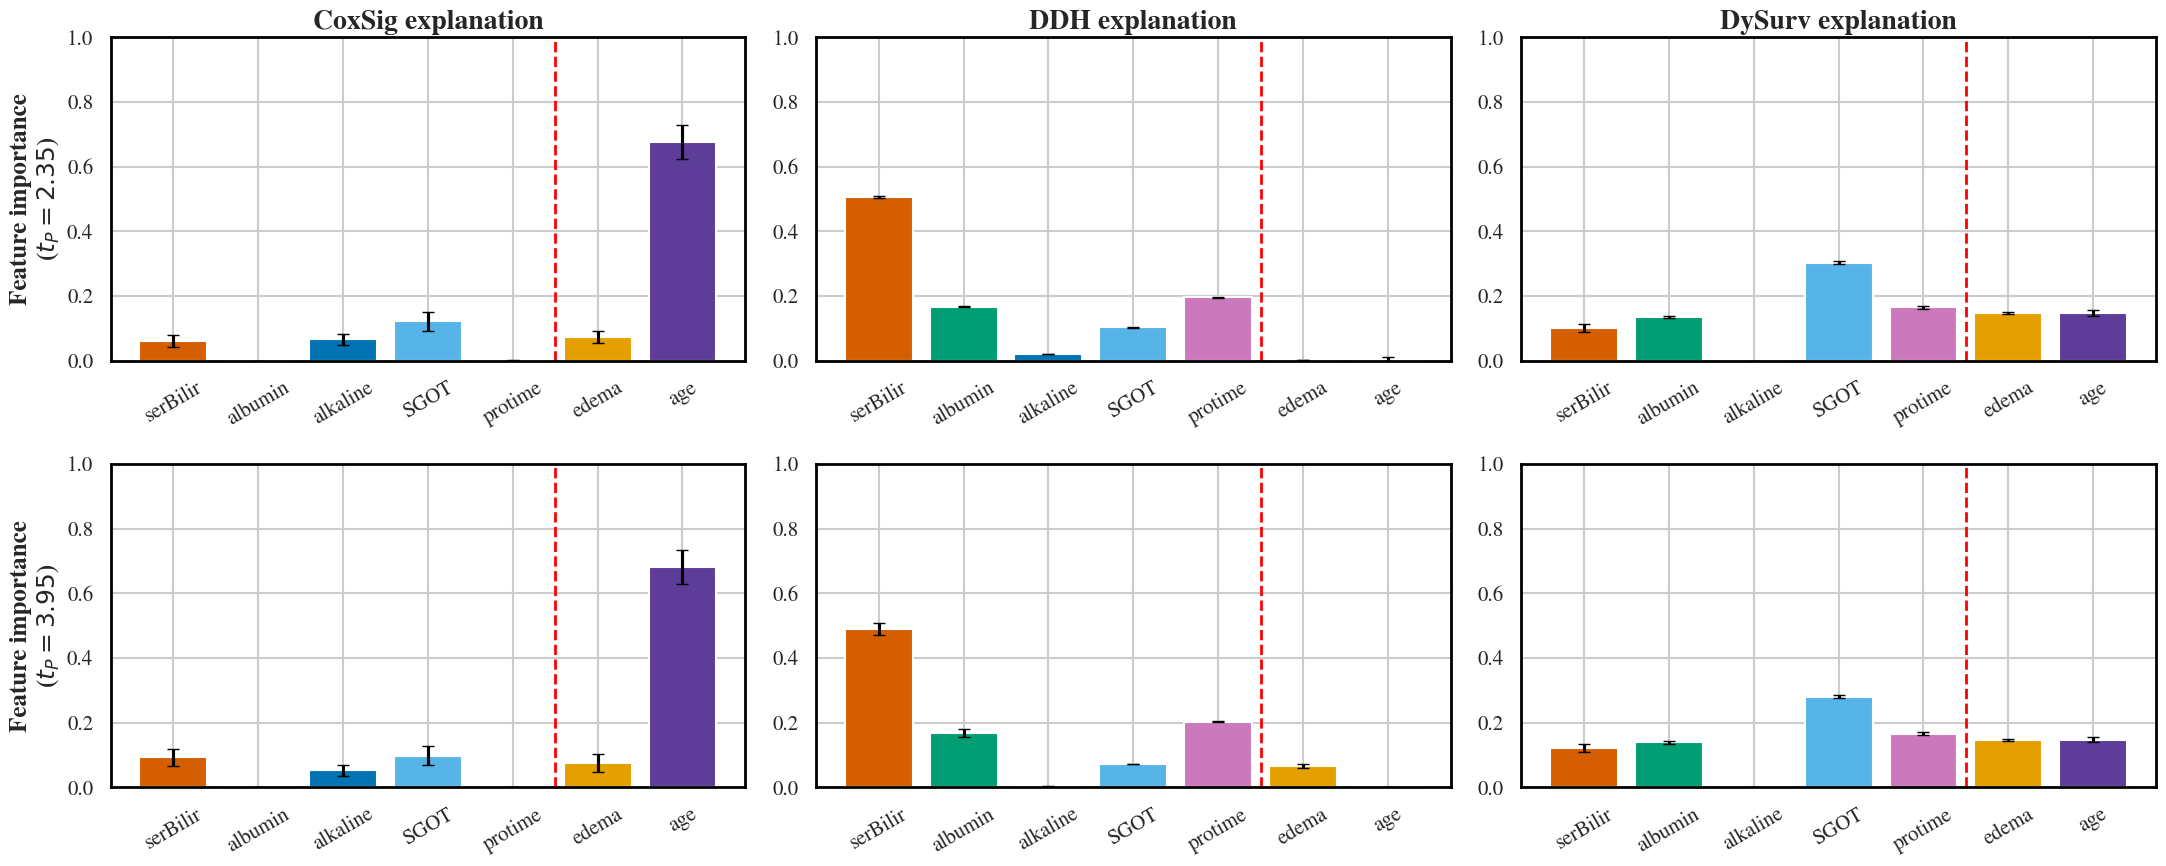

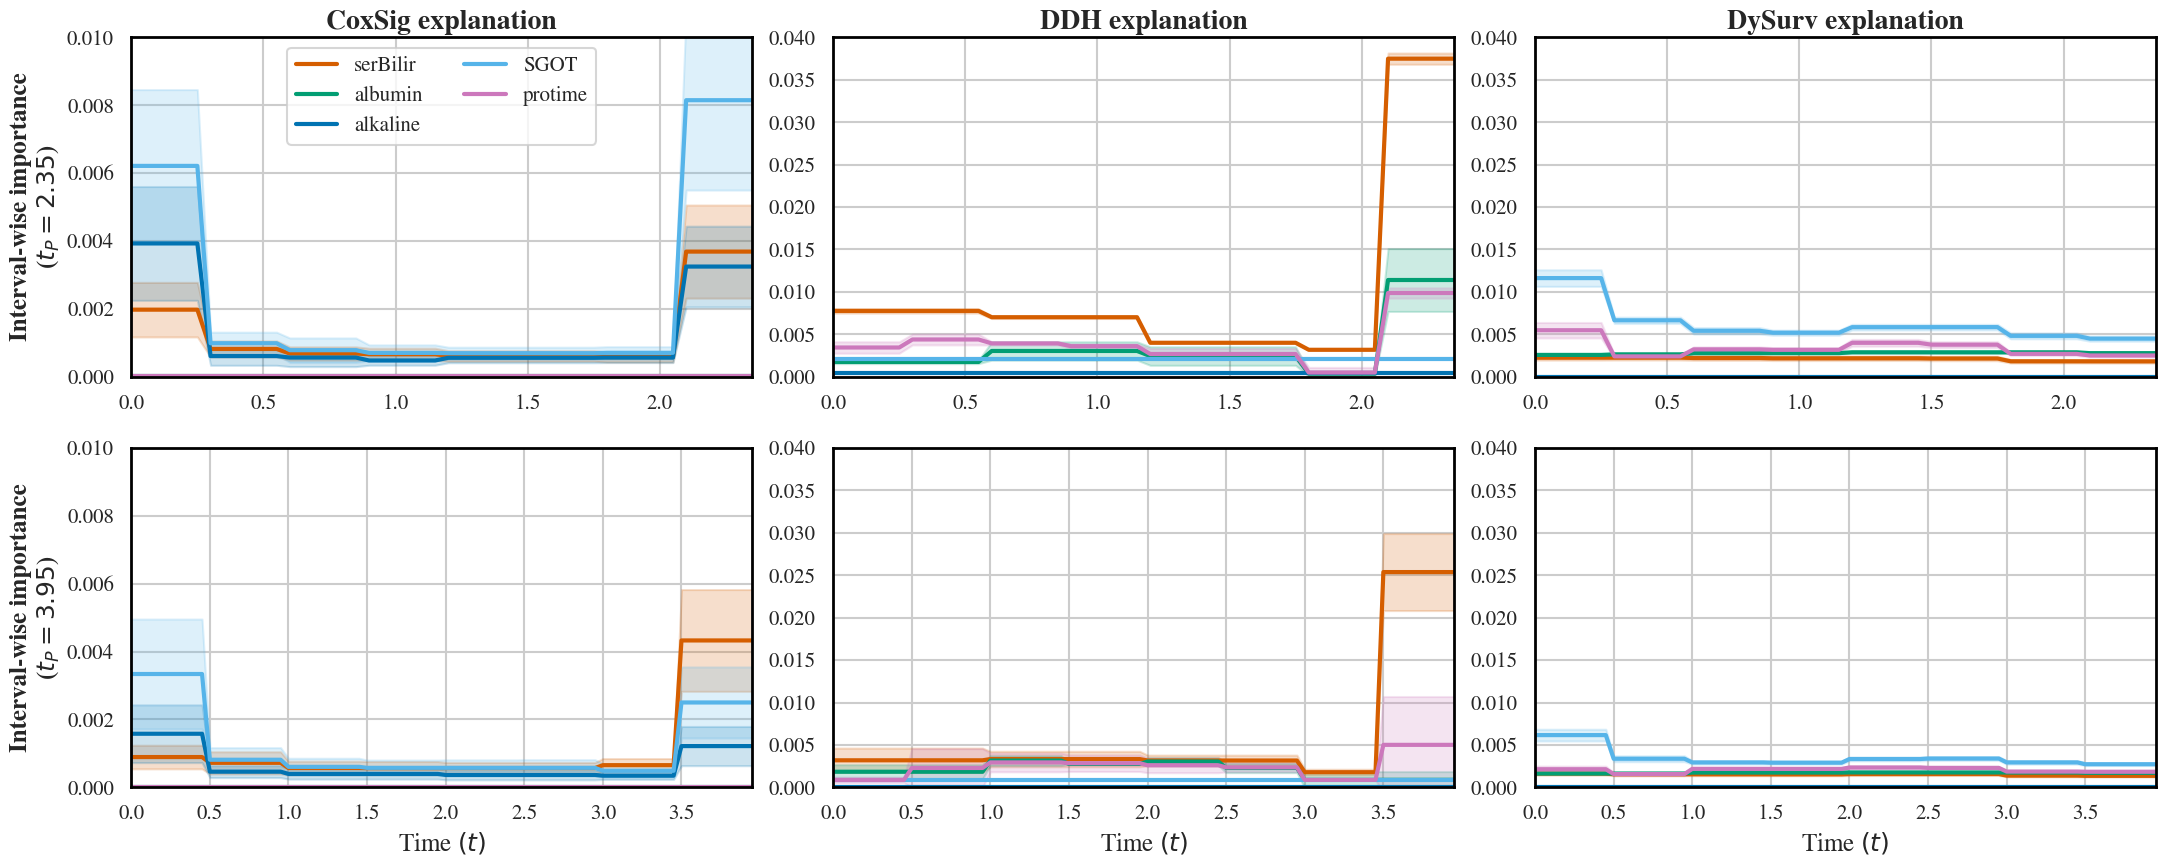

In [11]:
compare_models("med", "global", y_limits=[(0, 1)] * len(pred_times))
compare_models("med", "temporal", y_limits={
    "CoxSig": (0, 0.01), "DDH": (0, 0.04), "DySurv": (0, 0.04),
})

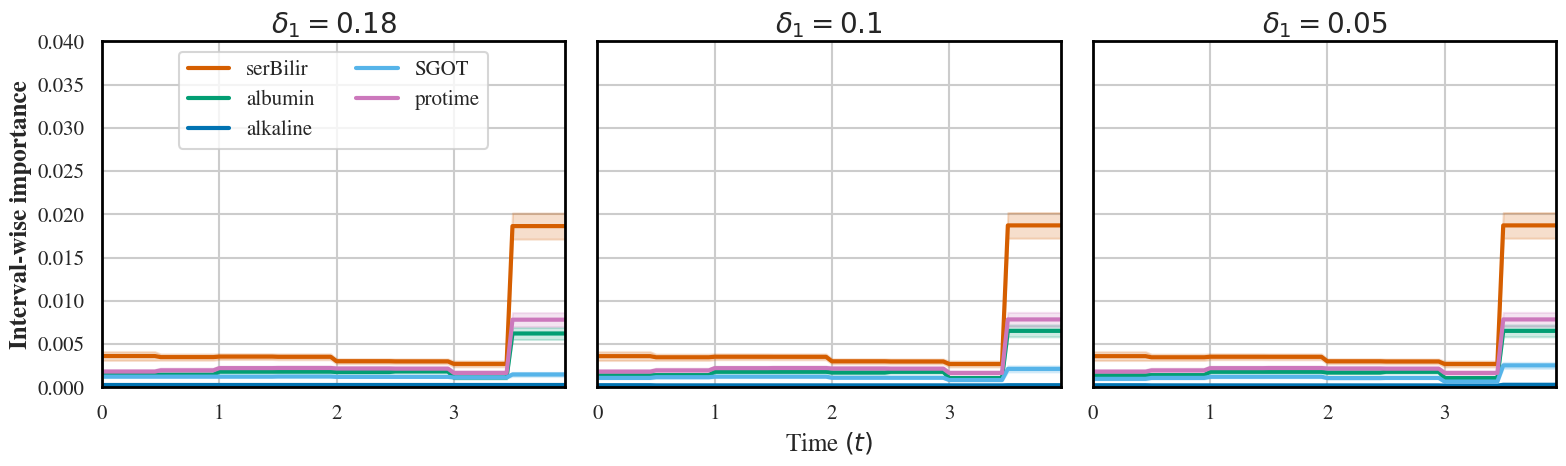

In [13]:
# ============================================================
# Sensitivity analysis: delta_1 for DDH
# ============================================================

delta_files = {
    0.18: "shap_PBC_mean_DDH_018.npy",
    0.10: "shap_PBC_mean_DDH_01.npy",
    0.05: "shap_PBC_mean_DDH_005.npy",
}

prediction_idx = 0
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)

for ax, (delta, filename) in zip(axes, delta_files.items()):

    # ---------- Load and summarize explanations ----------
    results = np.load(RESULT_DIR / filename, allow_pickle=True)
    if delta == 0.18:
        summary = importance_summary(results, prediction_idx)
    else:
        summary = importance_summary(results, prediction_idx)

    # ---------- Plot temporal importance ----------
    plot_temporal(
        ax,
        summary.temporal_mean,
        summary.temporal_ci,
        sampling_times,
        n_longi_feats,
        FEATURE_LABELS,
        COLORS,
    )

    style_axis(ax, rf"$\delta_1 = {delta:g}$", ylim=(0, 0.04))
    ax.set_xlim(0, explanation_end_time(summary))

axes[0].legend(ncols=2, fontsize=15, loc="upper center")
axes[0].set_ylabel("Interval-wise importance", fontsize=18, fontweight="semibold")
axes[1].set_xlabel("Time $(t)$", fontsize=18)

save_figure(fig, "shap_PBC_DDH_sensitive_analysis.pdf")